# 02. EDA：取得データの探索的分析

## 概要
01で収集した国会議事録データを詳細に分析し、
前処理方針を決定する。

## 目的
- データの品質・分布を把握する
- キーワードごとの発言傾向を確認する
- 発言者・会派・時系列のトレンドを可視化する
- 「公平」など汎用語のDEI文脈外混入を確認する
- 次工程（前処理・埋め込み）の方針を決定する

## 入力
- `data/speeches_raw.csv`

## 出力
- 各種可視化グラフ
- 前処理方針の決定

In [ ]:
# ============================================================
# ライブラリのインポートとデータ読み込み
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# IPAexフォントを直接読み込み　※AI利用　(プロンプト：図の文字化けを日本語にしたい。どんな設定ミスが考えられますか？)
font_path = "/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/japanize_matplotlib/fonts/ipaexg.ttf"
fm.fontManager.addfont(font_path)

# seabornの設定後にフォントを上書き
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "IPAexGothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (12, 6)

# 確認
print(plt.rcParams["font.family"])

# データ読み込み
df = pd.read_csv("../data/speeches_raw.csv")
print(f"データ数: {len(df)}件")

['IPAexGothic']
データ数: 18259件


## 1. 発言テキストの文字数分布
短すぎる発言（議事進行など）や長すぎる発言の分布を確認する。

=== 文字数の基本統計 ===
count    18259.000000
mean      1060.590229
std       1697.156981
min         23.000000
25%        378.000000
50%        577.000000
75%        988.000000
max      69567.000000
Name: text_length, dtype: float64


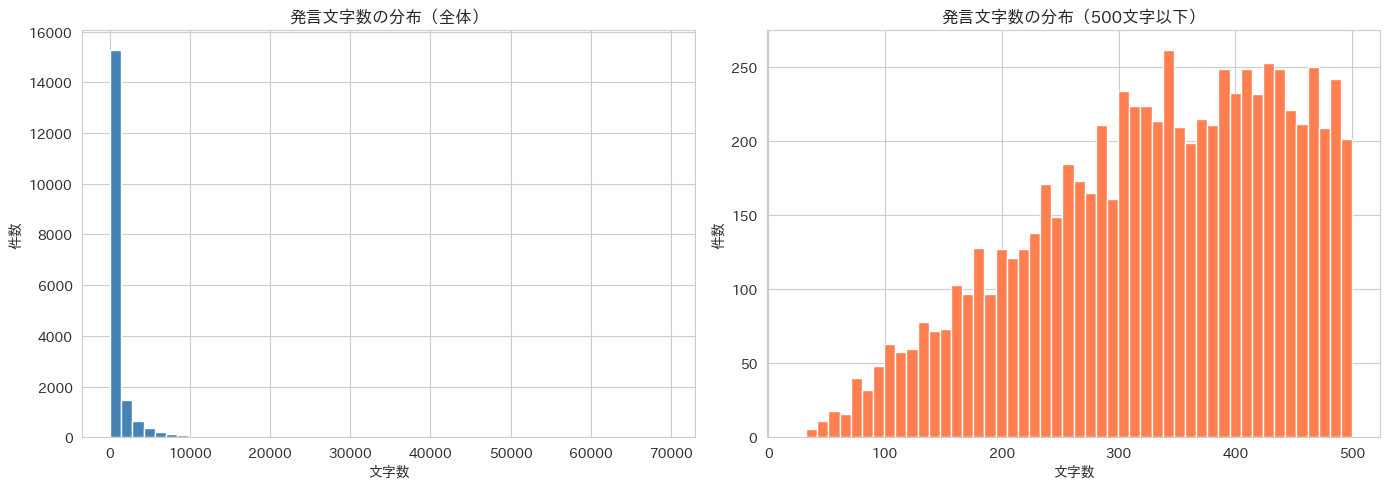


=== 100文字以下の発言例（5件） ===
['○たがや委員\u3000益税はあるんですか。これは岸田総理、もう答えは出ているんですが。不公平を是正するためにインボイス導入というのは、益税論争に終止符が打たれたことで、通用しません。', '○上川国務大臣\u3000多様性の観点というのは極めて重要であると認識しております。しっかりと取り組んでまいりたいと思います。', '○上野委員長\u3000次に、野田内閣府特命担当大臣、女性活躍担当大臣、こども政策担当大臣、孤独・孤立対策担当大臣から所信を聴取いたします。野田国務大臣。', '○中谷（一）委員\u3000今のところ、それでは、ティックトックのみを規制するということはないという理解でいいですね。外部サービス全体を見て包括的に判断するというお答えですよね。', '○串田誠一君\u3000そういう回答で、公平性を実現しようということではあると思うんですが、大変その対策難しいと思うんですけど、どんなことが考えられますか。']


In [10]:
# ============================================================
# 発言テキストの文字数を計算
# ============================================================
df["text_length"] = df["speech"].str.len()

print("=== 文字数の基本統計 ===")
print(df["text_length"].describe())

# 文字数分布をヒストグラムで可視化
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 全体の分布
axes[0].hist(df["text_length"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("発言文字数の分布（全体）")
axes[0].set_xlabel("文字数")
axes[0].set_ylabel("件数")

# 500文字以下に絞った分布（短い発言の確認）
axes[1].hist(df[df["text_length"] <= 500]["text_length"], 
             bins=50, color="coral", edgecolor="white")
axes[1].set_title("発言文字数の分布（500文字以下）")
axes[1].set_xlabel("文字数")
axes[1].set_ylabel("件数")

plt.tight_layout()
plt.show()

# 短い発言の例を確認
print("\n=== 100文字以下の発言例（5件） ===")
print(df[df["text_length"] <= 100]["speech"].head(5).tolist())

### 基本統計量および棒グラフから見る文字数分布の考察

**全体の分布**
- ほとんどの発言が1,000文字以下に集中(四分位数からも75%の発言が1,000文字以下)
- 最大69,567文字の外れ値が存在（議事録丸ごと取得の可能性）

**前処理方針**
- 50文字以下の発言は議事進行の可能性が高いため除去
- 5,000文字以上の発言は議事録丸ごとの可能性があるため除去
- 詳細は03_modeling.ipynbの前処理で実施

## 2. 前処理基準の検討
文字数分布から短すぎる・長すぎる発言の除去基準を決める。

In [11]:
# ============================================================
# 短い発言・長い発言の内容を実際に確認する
# ============================================================

# 50文字以下の発言を確認
print("=== 50文字以下の発言例 ===")
short = df[df["text_length"] <= 50]["speech"].head(5).tolist()
for s in short:
    print(f"・{s[:100]}")

print("\n=== 5000文字以上の発言例（冒頭200文字） ===")
long = df[df["text_length"] >= 5000]["speech"].head(3).tolist()
for s in long:
    print(f"・{s[:200]}")
    print()

=== 50文字以下の発言例 ===
・○伊藤岳君　大臣、ジェンダー不平等だと言えないんですか、この問題が。
・○副大臣（山本ともひろ君）　今お答えしたとおりで、公平性の確保から私は自主返納を決めました。
・○加藤国務大臣　新型コロナウイルス感染症緊急包括支援交付金の中で対応することにしております。
・○吉田忠智君　今官房長が言われた包括的な検証というのはどういう意味ですかね。
・○国務大臣（永岡桂子君）　包括的にということでございますから、そのとおりだと思っております。

=== 5000文字以上の発言例（冒頭200文字） ===
・○おおつき紅葉君　立憲民主党のおおつき紅葉と申します。（拍手）
　おととしの夏まで、私は、フジテレビの政治部の記者としてこの国会の中で取材をしていました。私生活では、小学校一年生と三年生の子供二人を育てる母親であります。急激に人口減少が進むふるさと小樽で立候補を決意したときには、既に衆院選まで僅か二か月でした。これがいかに無謀な挑戦か、政治部記者として重々承知をしておりました。でも、このままの政

・○三木圭恵君　日本維新の会・教育無償化を実現する会の三木圭恵です。
　私は、会派を代表し、岸田総理による米国公式訪問の帰朝報告について、全て総理に質問いたします。（拍手）
　自由で開かれた国際秩序が大きく揺らぐ中、日米両国首脳が結束し、安全保障や経済、エネルギー、宇宙など、多面的に協働していくことで合意するとともに、日米同盟をより強固にし、国際秩序の構築を担っていくと宣言した意義は大きいと評価

・○三谷参考人　一般社団法人全国消費者団体連絡会の事務局次長の三谷と申します。
　本日は、消費者契約法及び消費者裁判手続特例法の改正の審議に関し、意見を述べさせていただく機会をいただき、ありがとうございます。本来でしたら、事務局長の浦郷が発言させていただく予定でしたが、所用のやむを得ない事情により、私どもより意見を述べさせていただきます。
　全国消団連は、消費者団体の全国的な連絡組織で、全国四十



### 前処理方針の決定

**短い発言（50文字以下）について**
- 実際に確認すると「ジェンダー不平等だと言えないんですか、この問題が。」など
  DEI文脈として意味のある発言が含まれている
- → **除去しない**

**長い発言（5000文字以上）について**
- 長い演説・所信表明などが含まれる
- 埋め込みモデルは512トークン前後の上限があるため
  長すぎる発言は冒頭部分しか反映されない
- → **5000文字以上は冒頭1000文字に切り詰める**

**最終的な前処理方針**
- 文字数による除去は行わない
- 5000文字以上の発言は冒頭1000文字に切り詰める
- テキストクリーニング（発言者名・記号除去）は03で実施

## 3. キーワード別・年別トレンド分析
DEI関連キーワードの発言数が年々どう変化しているか確認する。

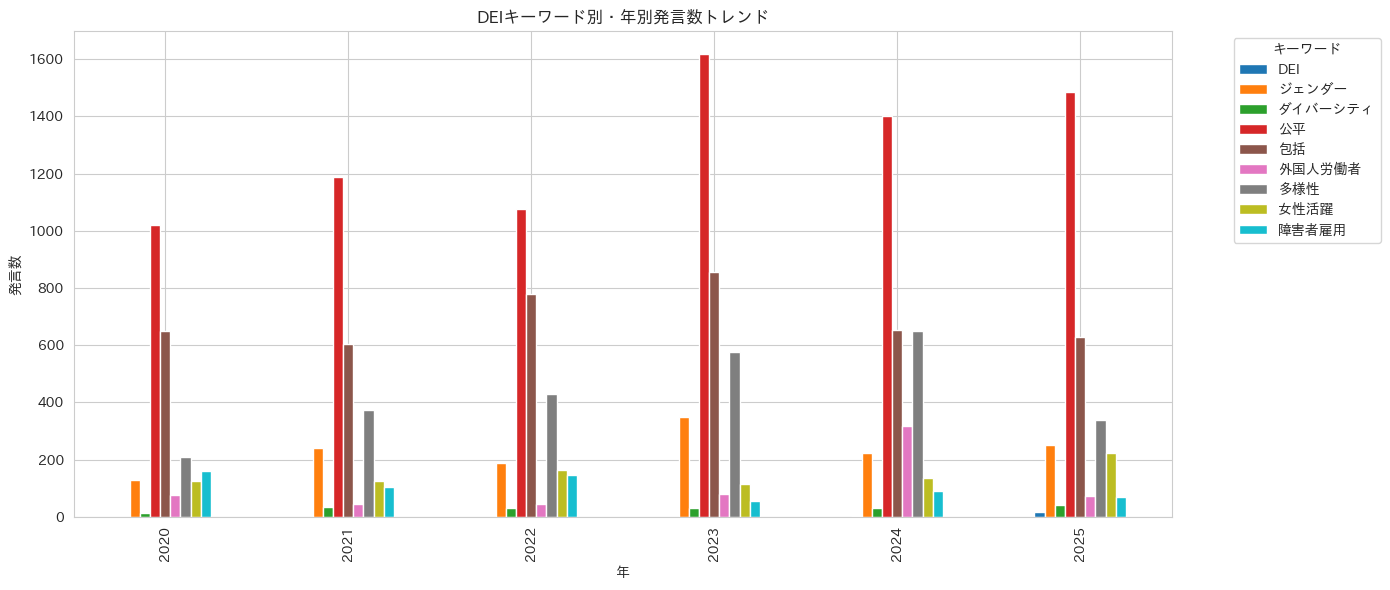

keyword_main  DEI  ジェンダー  ダイバーシティ    公平   包括  外国人労働者  多様性  女性活躍  障害者雇用
year                                                                  
2020            0    129       13  1019  650      75  209   124    159
2021            0    240       34  1187  605      46  375   125    103
2022            0    188       30  1077  778      45  431   165    146
2023            0    350       32  1617  855      78  577   116     56
2024            3    222       30  1403  653     318  648   135     89
2025           18    250       40  1484  630      73  337   222     70
保存完了: ../data/keyword_trend.png


In [13]:
# ============================================================
# 年別・キーワード別の発言数トレンド
# ============================================================

# 日付をdatetime型に変換して年を抽出
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

# キーワードが複数ある場合（例：ダイバーシティ|女性活躍）は
# 最初のキーワードを代表として使用
df["keyword_main"] = df["keyword"].str.split("|").str[0]

# 年別・キーワード別の発言数を集計
trend = df.groupby(["year", "keyword_main"]).size().unstack(fill_value=0)

# 可視化・保存
trend.plot(kind="bar", figsize=(14, 6), colormap="tab10")
plt.title("DEIキーワード別・年別発言数トレンド")
plt.xlabel("年")
plt.ylabel("発言数")
plt.legend(title="キーワード", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.savefig("../data/keyword_trend.png", dpi=150, bbox_inches="tight")
plt.show()

print(trend)
print("保存完了: ../data/keyword_trend.png")

### キーワード別・年別トレンドの考察

**全体の傾向**
- 「公平」が全年で圧倒的に多く、DEI文脈以外の発言が多数混入している可能性がある
- 「包括」・「多様性」は2023年・2024年にピークを迎えその後減少傾向
- 「ジェンダー」は2023年にピーク（350件）→社会的関心の高まりと一致
- 「DEI」というキーワード自体は2024年から登場（3件→18件）→概念の浸透が遅い
- 「ダイバーシティ」は全年を通じて少ない→カタカナより「多様性」が好まれる傾向
- ※2025年は取得期間途中のためデータが少ない可能性がある

**問題点**
- 「公平」は汎用語のため、インボイス・税制など非DEI文脈の発言が大量混入している
- → 03_modeling.ipynbの前処理でDEI文脈フィルタリングを検討する必要がある

## 4. 会派別・院別の発言傾向分析
どの会派・院がDEIについて多く発言しているか確認する。

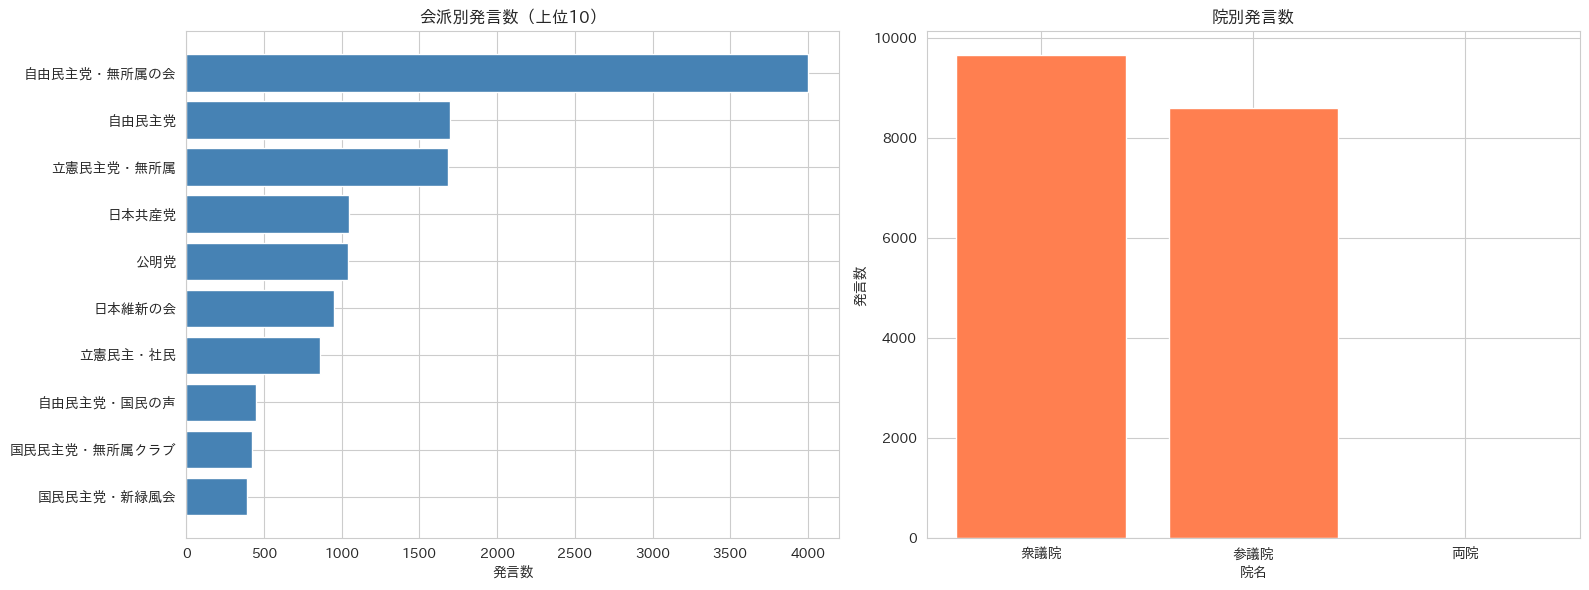

保存完了: ../data/group_house_distribution.png


In [14]:
# ============================================================
# 会派別・院別の発言数を集計・可視化
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 会派別発言数（上位10）
top_groups = df["speakerGroup"].value_counts().head(10)
axes[0].barh(top_groups.index, top_groups.values, color="steelblue")
axes[0].set_title("会派別発言数（上位10）")
axes[0].set_xlabel("発言数")
axes[0].invert_yaxis()

# 院別発言数
house_counts = df["nameOfHouse"].value_counts()
axes[1].bar(house_counts.index, house_counts.values, color="coral")
axes[1].set_title("院別発言数")
axes[1].set_xlabel("院名")
axes[1].set_ylabel("発言数")

plt.tight_layout()
plt.savefig("../data/group_house_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/group_house_distribution.png")

### 会派別・院別発言傾向の考察

**会派別**
- 「自由民主党・無所属の会」が約4,000件と突出して多い
  → 与党として答弁・質問の機会が多いためと考えられる
- 「自由民主党」「立憲民主党・無所属」がそれぞれ約1,700件で続く
- 野党（日本共産党・公明党・日本維新の会）も1,000件前後と一定の発言あり ※野党については2026年4月現在
- 01のEDAで出てきたspeakerGroupの欠損値（3,965件）はやはり大臣・参考人など無所属発言と推測

**院別**
- 衆議院（約9,500件）と参議院（約8,600件）でほぼ均等
- 「両院」という"分類"も存在する
- → 衆議院と参議院でバランスよくDEI関連発言が行われている

**クラスタリングへの示唆**
- 会派による発言傾向の違いがクラスタに反映される可能性がある
- 少数派クラスタに野党・少数会派の意見が含まれるか注目する

## 5. 「公平」キーワードのDEI文脈確認
「公平」は汎用語のため、DEI文脈以外の発言が混入していないか確認する。

In [15]:
# ============================================================
# 「公平」キーワードの発言内容をサンプル確認
# DEI文脈かどうかを判断する
# ============================================================

# 「公平」単独でヒットした発言をランダムに10件確認
kouhei = df[df["keyword_main"] == "公平"]["speech"].sample(10, random_state=42)

for i, text in enumerate(kouhei):
    print(f"--- {i+1}件目 ---")
    print(text[:150])
    print()

--- 1件目 ---
○関（健）委員　立憲民主党の関健一郎です。
　質問の機会をいただきまして、ありがとうございました。冒頭、委員長並びに与野党の理事の皆様に御礼を申し上げます。
　プラスチックの法案ということなので、プラスチックが出ないように何とかならないかなということを思ったら、地元の絵が得意な方が私が描くわよと

--- 2件目 ---
○梅村聡君　そうしますと、これ非常に、先ほども申し上げましたけれども、昨年のドナーの数が百三十二人と、これ、もちろん過去最高ではあるんですけれども、しかし、諸外国、例えばアメリカとかヨーロッパとか、それからお隣の韓国と含めても、ドナーの数という面からいえば、アメリカのまだ五十分の一、お隣の韓国でもま

--- 3件目 ---
○参考人（菊池馨実君）　ありがとうございます。
　先ほど申しましたのは、これはやはり教育政策として正面から取り上げていただきたいなと思っております。
　私の勤める早稲田大学、私立大学ですけど、裕福な子女ばっかりじゃないかと思われるかもしれません。そんなことはないです。本当に厳しい状況の中で通って

--- 4件目 ---
○泉委員　ふえているのは当たり前じゃないですか。ふえていなかったら、とんでもない事業ですよ、七千億もかけて。ちょっとぐらいふえるのは決まっているじゃないですか、そんなもの。そんな話をしているんじゃないでしょう。費用対効果だとか、そして公平性だとか、そういうものがおかしいという話をしている。いや、別に

--- 5件目 ---
○上川国務大臣　私も、この検察の理念、絶えず読ませていただきながら来ました。この当時、理念を作り上げられた背景がございましたので、これにかける検察の皆さんの思いというものが体現されている、こう思って、先回もその旨の発言をしたところでございます。
　読ませていただきます。「権限の行使に際し、いかなる

--- 6件目 ---
○徳茂雅之君　自由民主党の徳茂雅之です。
　私は、自民、公明を代表し、ただいま議題となりましたデジタル改革関連法案に対し、賛成の立場から討論を行います。
　冒頭、新型コロナウイルス感染症によりお亡くなりになられた方々に対し、哀悼の意を表します。また、闘病を続けておられる皆様にお見舞いを申し上げま

--- 7件目 ---
○川田龍平君　立憲民主

### 「公平」キーワードの確認結果

サンプル10件を確認したところ、DEI文脈の発言はほぼ存在しなかった。
具体的にはプラスチック法案・臓器ドナー・検察・地方財政など
DEIと無関係なトピックで「公平」という単語が使われていた。
また「公平」は部分一致検索のため「不公平」「公平性」「公平感」なども混入し、さらにノイズが多い。

**対応方針**
「公平」はDEI分析のキーワードとして不適切と判断し、
03_modeling.ipynbの前処理段階で除外する。

これにより分析対象は以下に絞られる：
- ダイバーシティ、多様性、女性活躍、ジェンダー、包括、障害者雇用、外国人労働者、DEI

## 6. 「包括」キーワードのDEI文脈確認
「包括」も汎用語のため、DEI文脈以外の発言が混入していないか確認する。

In [16]:
# ============================================================
# 「包括」キーワードの発言内容をサンプル確認
# ============================================================
katsura = df[df["keyword_main"] == "包括"]["speech"].sample(10, random_state=42)

for i, text in enumerate(katsura):
    print(f"--- {i+1}件目 ---")
    print(text[:150])
    print()

--- 1件目 ---
○山谷えり子君　内閣府に新設する部局の規模、人員、予算、非常に重要であります。基本方針の策定は、この新部局と国家安全保障局が連携して行うこととなっています。現在、太陽光やリゾート地、雑種地、原野等買収事例の統計はなくて、また日本法人等のダミーのケースも分からないということですが、関係省庁の所管業務と

--- 2件目 ---
○足立委員　家賃の話をおっしゃいましたが、でも、それは福祉の分野だけの問題ではなくて、さっきあったみたいに、いろいろな仕組みをつくれば、貸しやすい仕組みをつくれば、だって、使われずに置いておくよりも幾らかで貸す方が大家さんにとっていいに決まっているわけだから、それはやはり私は、住宅政策の問題として処

--- 3件目 ---
○山添拓君　これはですね、やっぱりまともに伝えているのかどうかすら疑わしい話だと思うんですね。
　北朝鮮は、二〇一八年の南北首脳会談、米朝首脳会談でも非核化を誓い、平和構築のための対話や交渉を約束しています。この自らの合意に立ち返るべきだと、だから交渉に応じるべきだと、こういうふうに伝えるべきだと

--- 4件目 ---
○小倉議員　宗教の自由を始めとする憲法上の人権保障の要請から、宗教法人の財産の管理に対しては制約を加えるということは慎重にも慎重を期したものでなければならないということは先ほど申し上げたとおりであります。
　宗教法人の財産は、信者の信仰の表現でもある寄附等の結果として形成され、主として宗教的活動の

--- 5件目 ---
○阿達雅志君　ただいま議題となりました条約三件につきまして、外交防衛委員会における審査の経過と結果を御報告申し上げます。
　まず、日米宇宙協力に関する枠組協定は、我が国とアメリカ合衆国との間において、平和的目的のための月その他の天体を含む宇宙空間の探査及び利用における協力に関する基本事項を包括的に

--- 6件目 ---
○国務大臣（田村憲久君）　矢田わか子議員にお答え申し上げます。
　これまでの雇用対策と保健所などの公的部門における失業者の採用についてお尋ねがありました。
　コロナ禍においても、我が国の完全失業率は直近で二・九％と、主要国の中で最も低い水準で推移しておりますが、国民の皆さんの雇用と暮らしを守って

--- 7件目 ---
○盛山正仁君　ただ

### 「包括」キーワードの確認結果

サンプル10件を確認したところ、DEI文脈の発言は存在しなかった。
安全保障・住宅政策・宗教法人・カーボンニュートラルなど
DEIと無関係なトピックで「包括的に」「包括支援」などの形で使われていた。

**対応方針**
「包括」も「公平」と同様にDEI分析のキーワードとして不適切と判断し、
03_modeling.ipynbの前処理段階で除外する。

これにより最終的な分析対象キーワードは以下に絞られる：
- ダイバーシティ、多様性、女性活躍、ジェンダー、障害者雇用、外国人労働者、DEI

## 7. EDAまとめと前処理方針の確定
EDA全体を通じて判明した事項と、03_modeling.ipynbへの引き継ぎ事項をまとめる。

In [17]:
# ============================================================
# 前処理後のデータ件数を試算
# ============================================================

# 除外キーワード
exclude_keywords = ["公平", "包括"]

# 除外後のデータ数確認
df_filtered = df[~df["keyword_main"].isin(exclude_keywords)]

print(f"除外前: {len(df)}件")
print(f"除外後: {len(df_filtered)}件")
print(f"除外件数: {len(df) - len(df_filtered)}件")
print(f"\n残存キーワード別件数:")
print(df_filtered["keyword_main"].value_counts())

除外前: 18259件
除外後: 6301件
除外件数: 11958件

残存キーワード別件数:
keyword_main
多様性        2577
ジェンダー      1379
女性活躍        887
外国人労働者      635
障害者雇用       623
ダイバーシティ     179
DEI          21
Name: count, dtype: int64


### EDAまとめと前処理方針の確定

#### データ品質の確認結果
| 項目 | 内容 |
|------|------|
| 総発言数 | 18,259件 |
| 除外キーワード（公平・包括） | 11,958件 |
| **分析対象** | **6,301件** |

#### 除外理由
- 「公平」：DEI無関係のトピック（税制・法案等）に頻出する汎用語
- 「包括」：「包括的に」「包括支援」など非DEI文脈で多用される汎用語
- 両キーワードとも部分一致検索のためノイズが特に多い

#### 残存キーワードの分布
- 「多様性」が最多（2,577件）
- 「DEI」は21件と少ない → 概念としての浸透がまだ低い
- 「ダイバーシティ」（179件）と「多様性」（2,577件）の差 
  → 国会では英語より"日本語表現"が好まれる傾向

#### 03_modeling.ipynbへの引き継ぎ事項
1. 「公平」「包括」を除外した6,301件を分析対象とする
2. 5,000文字以上の発言は冒頭1,000文字に切り詰める
3. 発言者名（「○○君」など）をテキストから除去する
4. Round1→2→3の順でモデルを改善する(仕様書より)

In [18]:
# ============================================================
# SDGsキーワードの件数を試しに確認する
# ============================================================
import requests

url = "https://kokkai.ndl.go.jp/api/speech"
params = {
    "any": "SDGs",
    "from": "2020-01-01",
    "until": "2025-12-31",
    "maximumRecords": 1,
    "recordPacking": "json"
}

response = requests.get(url, params=params)
data = response.json()
print(f"SDGs 総件数: {data['numberOfRecords']}件")

SDGs 総件数: 1235件


In [19]:
# ============================================================
# SDGs発言の内容をサンプル確認
# DEI文脈かどうかを判断する
# ============================================================
import time

params = {
    "any": "SDGs",
    "from": "2020-01-01",
    "until": "2025-12-31",
    "maximumRecords": 10,
    "recordPacking": "json"
}

response = requests.get(url, params=params)
data = response.json()

for i, r in enumerate(data["speechRecord"]):
    print(f"--- {i+1}件目 ---")
    print(r["speech"][:150])
    print()

--- 1件目 ---
○神谷委員　ただいま議題となりました決議案につきまして、提出者を代表いたしまして、その趣旨を御説明申し上げます。
　案文の朗読により趣旨の説明に代えさせていただきます。
　　　　令和八年度畜産物価格等に関する件（案）
　　我が国の畜産・酪農経営は、担い手の高齢化、後継者不足が進行しており、生産

--- 2件目 ---
○政府参考人（長井俊彦君）　お答えいたします。
　アニマルウエルフェアは、家畜を丁寧に取り扱うなど適正な飼養管理を行うことで、家畜のストレスや疾病を減少させ、家畜の本来持つ能力を発揮させる取組でありまして、畜産物の輸出拡大やＳＤＧｓへの対応等からもその推進が求められております。
　このため、我が

--- 3件目 ---
○石垣のりこ君　私は、自由民主党、立憲民主・社民・無所属、国民民主党・新緑風会、公明党、日本維新の会、参政党及び日本共産党の各派共同提案による畜産物価格等に関する決議案を提出いたします。
　案文を朗読いたします。
　　　　畜産物価格等に関する決議（案）
　　我が国の畜産・酪農経営は、担い手の高

--- 4件目 ---
○山添拓君　今、中国軍機によるレーダー照射などが起こり、これは偶発的な衝突にもつながりかねない危険な行為ですから、私も冷静な対応を強く求めたいと思います。
　同時に、今起きている対立と緊張は総理の答弁がきっかけです。改めて撤回すべきだということは求めておきたいと思います。
　危機をあおり、軍備を

--- 5件目 ---
○山添拓君　憲法九条について何らの言及もない、こんな危ういことはないと思いますよ。私は、それでは果てしない軍拡競争だと思います。
　一方で軍事費の増加と、他方でＳＤＧｓの財源不足、二つの方向を転換させることが人類の生存に不可欠だと、この国連の指摘を重く受け止めて、大軍拡ありきを転換するよう強く求め

--- 6件目 ---
○茂木国務大臣　グリーンエキスポ二〇二七、これは「幸せを創る明日の風景」、これをテーマに、国際的な園芸文化の普及であったりとか、花や緑にあふれる暮らしの実現に向けて、気候変動への対応であったりとか生物多様性の保全等の社会的な課題解決への貢献を目的に、先生の御地元でもあります神奈川、横浜で開催をされる

--- 7件目 ---
○黄川田国務大臣　こども政策、

### SDGsキーワードの検討結果

- 総件数1,235件と一定の発言数があるため追加を検討した
- サンプル確認の結果、畜産・安全保障・軍備など
  DEIと直接関係しない文脈でSDGsが言及されるケースが多数
- SDGsは概念が広すぎるため今回のDEI分析には追加しない(DEI関連は5と10のみ該当か)
- 分析対象は6,301件のまま維持する